# Adversarial Search: Solving Tic-Tac-Toe with Monte Carlo Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* We enhance Pure Monte Carlo Search by using the upper confidence bound (UCB1) selection policy. That is, we use UCB1 to determine for which action to perform the next playout. This will allow the algorithm to focus on actions here it needs to collect more information. Note that complete Upper Confidence Bounds applied to Trees (UCT) creates a tree and the expand step in the code needs to be added. The tree branch for the chosen move is preserved and used for future moves.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py). 

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Monte Carlo Search with Upper Confidence Bound

See AIMA page 163. 

We enhance pure Monte Carlo Search by using UCB1 as a __selection policy__. This can be seen as a 
restricted version of UTC: 
* Only build a tree of depth 1 and use the UBC1 selection policy.
* Use a random playout policy.


__Note on the playout policy:__ We use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with a good __playout policy__ (e.g., manually created heuristics or a neural [network learned by self-play using reinforcement learning](https://towardsdatascience.com/how-to-teach-an-ai-to-play-games-deep-reinforcement-learning-28f9b920440a)).

## Simulate playouts

In [3]:
import numpy as np

# Đặt seed để chạy lại ra đúng kết quả này (các lượt đánh thử ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [4]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: 
            return u
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

-1
1
1


## Upper Confidence Bound Applied to Trees (Restricted to Depth 1)

In [5]:
import pandas as pd
import math

DEBUG = 1

def UCT_depth1(board, N = 100, player = 'x'):
    """Upper Confidence bound applied to Trees for limited tree depth of 1. 
    Simulation budget is N playouts."""
    global DEBUG
    
    C = math.sqrt(2) # tradeoff constant
    
    # the tree is 1 action deep
    acts = actions(board)
    
    u = [0] * len(acts) # total utility through actions
    n = [0] * len(acts) # number of playouts through actions
    n_parent = 0 # total playouts so far (i.e., number of playouts through parent)
    
    # make sure we try each action once
    UCB1 = [+math.inf] * len(acts) 
    
    for i in range(N):

        # Select
        action_id = UCB1.index(max(UCB1))
    
        # Expand
        # UTC would expand the tree. We keep the tree at depth 1, essentially performing
        # Pure Monte Carlo search with an added UCB1 selection policy. 
        
        # Simulate
        p = playout(board, acts[action_id], player = player)
    
        # Back-Propagate (i.e., update counts and UCB1)
        u[action_id] += p
        n[action_id] += 1
        n_parent += 1
        
        for action_id in range(len(acts)):
            if n[action_id] > 0:
                UCB1[action_id] = u[action_id] / n[action_id] + C * math.sqrt(math.log(n_parent) / n[action_id])
    
    # return action with largest number of playouts 
    action = acts[n.index(max(n))]
    
    if DEBUG >= 1: 
        print(pd.DataFrame({'action':acts, 
                            'total utility':u, 
                            '# of playouts':n, 
                            'UCB1':UCB1}))
        print()
        print(f"Best action: {action}")
    
    
    return action

In [6]:
# Đặt seed để chạy lại ra đúng kết quả này (UCT_depth1 ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [7]:
board = empty_board()
display(board)

%timeit -n 1 -r 1 UCT_depth1(board, N = 1000)

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

   action  total utility  # of playouts      UCB1
0       0             31            103  0.667210
1       1              1             33  0.677336
2       2             57            153  0.673044
3       3             13             63  0.674637
4       4            146            313  0.676547
5       5             15             69  0.664856
6       6             71            173  0.692997
7       7             -5             14  0.636246
8       8             20             79  0.671351

Best action: 4
303 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét.** Đây là bảng của UCB1 trên **bàn trống** với 1,000 ván đánh thử. Khác với Pure Monte Carlo (chia đều khoảng 111 ván cho mỗi ô), UCB1 **không chia đều**: ô 4 (chính giữa) được 313 ván, ô 6 được 173, ô 2 được 153, còn ô 7 chỉ 14 ván và ô 1 chỉ 33 ván. Những ô có điểm trung bình thấp bị bỏ dần, ô có điểm cao được thử thêm. Ô được chọn là ô có nhiều ván nhất, ở đây là ô 4.

## Some Tests

### x is about to win (play 8)

In [8]:
# Đặt seed để chạy lại ra đúng kết quả này (UCT_depth1 ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


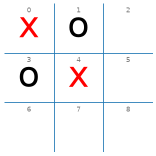


   action  total utility  # of playouts      UCB1
0       2             16             19  1.538349
1       5             15             19  1.485717
2       6             16             19  1.538349
3       7              8             12  1.542754
4       8             31             31  1.545076

Best action: 8
20.5 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [9]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board)

**Nhận xét.** "x sắp thắng", N = 100: ô 8 (thắng ngay) có tổng điểm 31 trên 31 ván (ván nào cũng thắng) và được nhiều ván nhất, nên UCB1 chọn đúng ô 8. Các ô 2, 5, 6 được 19 ván mỗi ô, ô 7 chỉ 12 ván.

### o is about to win

In [10]:
# Đặt seed để chạy lại ra đúng kết quả này (UCT_depth1 ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


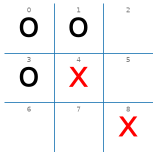


   action  total utility  # of playouts      UCB1
0       2             -4            250  0.219079
1       5            -16             32  0.157065
2       6             27            699  0.179214
3       7            -13             19  0.168510

Best action: 6
105 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [11]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

**Nhận xét.** "o sắp thắng", N = 1000: UCB1 dồn 699 ván cho ô 6 và 250 ván cho ô 2, tức là hai ô chặn (mỗi ô chặn một đường của o), còn hai ô không chặn (ô 5 và ô 7) chỉ 32 và 19 ván. Lượt đánh thử chạy tập trung vào hai nước đáng thử. Thực ra mọi nước đều thua nếu o chơi đúng, nhưng hai ô 2 và 6 là hai ô "đỡ thua" nhất.

### x can draw if it chooses 7

In [12]:
# Đặt seed để chạy lại ra đúng kết quả này (UCT_depth1 ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


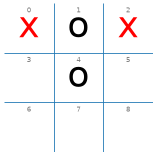


   action  total utility  # of playouts      UCB1
0       3             -8            101  0.290640
1       5            -11             61  0.295575
2       6            -12             28  0.273861
3       7            132            795  0.297863
4       8            -10             15  0.293039

Best action: 7
191 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [13]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

**Nhận xét.** "x cần đi 7 để hòa", N = 1000: UCB1 dồn **795 / 1000 ván** cho ô 7 (nước đúng duy nhất), còn các ô sai chỉ 15 - 101 ván. Ô 7 có tổng điểm +132, các ô sai đều âm. Xem kỹ cách chia này ở mục "Xem UCB1 chia lượt đánh thử như thế nào" ở cuối notebook.

### Empty board: Only a draw an be guaranteed

In [14]:
# Đặt seed để chạy lại ra đúng kết quả này (UCT_depth1 ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


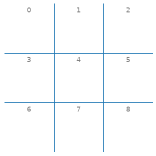


   action  total utility  # of playouts      UCB1
0       0              3             10  1.259705
1       1              4             12  1.209420
2       2              9             19  1.169928
3       3              2              9  1.233840
4       4              5             15  1.116929
5       5              0              8  1.072983
6       6              6             15  1.183596
7       7             -2              5  0.957228
8       8             -1              7  1.004210

Best action: 2
32.4 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


   action  total utility  # of playouts      UCB1
0       0            106            302  0.588491
1       1              9             78  0.582706
2       2             59            202  0.582473
3       3              8             77  0.574243
4       4           1977           3784  0.589558
5       5             58            198  0.586242
6       6              5             65  0.588848
7       7             51            182  0.586154
8       8             22            112  0.586419

Best action: 4
1.5 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [15]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%timeit -n1 -r1 UCT_depth1(board, N = 100)
%timeit -n1 -r1 UCT_depth1(board, N = 5000)

**Nhận xét.** Bàn trống với N = 100: ván đánh thử chia khá đều (5 - 19 ván mỗi ô) và UCB1 chọn **ô 2** (19 ván), chưa phải ô giữa, vì 100 ván là quá ít để phân biệt các ô. Khi tăng lên N = 5,000, UCB1 dồn 3,784 ván (khoảng 76%) cho ô 4 và chọn ô 4, còn các ô 1, 3 và 6 chỉ 65 - 78 ván mỗi ô. Giống Pure Monte Carlo: N đủ lớn mới chọn đúng ô giữa. Với N = 5,000 chạy khoảng 1.5 giây.

### A bad situation

In [16]:
# Đặt seed để chạy lại ra đúng kết quả này (UCT_depth1 ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


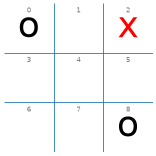


   action  total utility  # of playouts      UCB1
0       1             -4              6  0.572307
1       3             -4             10  0.559705
2       4             13             62  0.595104
3       5             -4             12  0.542754
4       6             -4              4  0.517427
5       7             -4              6  0.572307

Best action: 4


4

In [17]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)


print()
display(UCT_depth1(board))

**Nhận xét.** "Tình huống bất lợi": UCB1 dồn 62 trên 100 ván cho ô 4, các ô còn lại chỉ 4 - 12 ván mỗi ô, nên chọn ô 4. Giống Pure Monte Carlo ở Bài 5: vì ván đánh thử cho o đi bừa, ô 4 trông tốt hơn thực tế. UCB1 cũng ngầm giả sử đối thủ chơi ngẫu nhiên.

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [18]:
def ucb1_10_player(board, player = 'x'):
    action = UCT_depth1(board, N = 10, player = player)
    return action

def ucb1_100_player(board, player = 'x'):
    action = UCT_depth1(board, N = 100, player = player)
    return action

In [19]:
# Đặt seed để chạy lại ra đúng kết quả này (100 ván đấu ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [20]:
DEBUG = 0
print("UCB1 (10) vs. random:")
%timeit -n1 -r1 display(play(ucb1_10_player, random_player))

print()
print("random vs. UCB1 (10):")
%timeit -n1 -r1 display(play(random_player, ucb1_10_player))

UCB1 (10) vs. random:


{'x': 90, 'o': 5, 'd': 5}

695 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (10):


{'x': 23, 'o': 61, 'd': 16}

565 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét (UCB1 N = 10 đấu Random).** Với seed `20261110`, UCB1 (10) đi trước thắng 90 ván, hòa 5, thua 5. Đi sau thì thắng 61 ván, hòa 16, thua 23 (kết quả của `play` tính theo `'x'`/`'o'`: ở dòng "random vs. UCB1 (10)" thì o là UCB1, nên `'o': 61` là số ván UCB1 thắng). Số này hơi khác Bảng 3 bên dưới (67 thắng) vì ở ô này hai lượt đấu dùng chung một seed ban đầu (lượt sau tiếp tục dãy số ngẫu nhiên của lượt trước), còn Bảng 3 đặt lại seed trước mỗi lượt.

In [21]:
# Đặt seed để chạy lại ra đúng kết quả này (100 ván đấu ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [22]:
DEBUG = 0
print("UCB1 (100) vs. random:")
%timeit -n 1 -r 1 display(play(ucb1_100_player, random_player))

print()
print("random vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(random_player, ucb1_100_player))

UCB1 (100) vs. random:


{'x': 97, 'o': 0, 'd': 3}

6.33 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (100):


{'x': 3, 'o': 89, 'd': 8}

5.18 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét (UCB1 N = 100 đấu Random).** UCB1 (100) đi trước thắng 97 ván, hòa 3 và không thua. Đi sau thắng 89 ván, hòa 8, thua 3 (ở dòng "random vs. UCB1 (100)", `'o': 89` là số ván UCB1 thắng). Tăng từ N = 10 lên N = 100 thì thắng nhiều hơn rõ (khi đi trước: 90 → 97 ván; khi đi sau: 61 → 89 ván) và gần như không thua. Đổi lại chậm hơn khoảng 8 - 9 lần (khoảng 6.4 giây so với 0.7 giây cho 100 ván khi đi trước).

In [23]:
# Đặt seed để chạy lại ra đúng kết quả này (100 ván đấu ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [24]:
DEBUG = 0
print("UCB1 (100) vs. UCB1 (10):")
%timeit -n 1 -r 1 display(play(ucb1_100_player, ucb1_10_player))

print()
print("UCB1 (10) vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(ucb1_10_player, ucb1_100_player))

UCB1 (100) vs. UCB1 (10):


{'x': 86, 'o': 2, 'd': 12}

6.94 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

UCB1 (10) vs. UCB1 (100):


{'x': 36, 'o': 47, 'd': 17}

5.9 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét (UCB1 đấu UCB1).** UCB1 (100) đi trước thắng UCB1 (10) 86 ván, hòa 12, thua 2. Khi đổi chỗ, UCB1 (10) đi trước thắng 36 ván, hòa 17, và UCB1 (100) thắng 47 ván (ở dòng "UCB1 (10) vs. UCB1 (100)", `'o': 47` là số ván UCB1 (100) thắng). Bên có N lớn hơn luôn thắng nhiều hơn, nhưng khi phải đi sau thì chênh lệch nhỏ hơn (47 so với 36), vì người đi trước vốn có lợi thế.

## Bài 6 — UCB1 so với Pure Monte Carlo

Phần này là phần **thêm mới** của Toàn Thắng (các ô gốc của thầy ở trên giữ nguyên, mình chỉ chèn thêm ô đặt seed và ô nhận xét). Theo đề (Bài 6), ta cần:

* chạy `ucb1_10_player` và `ucb1_100_player` trên **các trạng thái kiểm thử** và khi **đấu với `random_player`**;
* **so sánh với Pure Monte Carlo** ở Bài 5;
* trả lời hai câu: UCB1 cân bằng *exploration* và *exploitation* thế nào? Khi số lần mô phỏng tăng thì quyết định có ổn định hơn không?

Vài từ cần biết:

* **Playout** = "đánh thử một ván ngẫu nhiên tới hết".
* **Exploration** (khám phá) = thử những nước ít được thử, phòng khi nước đó thật ra tốt.
* **Exploitation** (khai thác) = dồn sức vào nước đang có vẻ tốt.
* **UCB1** là một công thức chấm điểm cho từng nước, để quyết định lượt đánh thử tiếp theo dành cho nước nào. Pure Monte Carlo thì chia **đều** N lượt cho mọi nước.

**Cách chạy lại.** Mọi chỗ có ngẫu nhiên đều đặt seed ngay trước đó (seed gốc `20261110`; khi lặp 20 lần thì lần `r` dùng seed `20261110 + r`). Chạy lại với cùng seed sẽ ra đúng số này; đổi seed thì số đổi một chút. **Thời gian đo trên máy của người chạy**, máy khác sẽ khác.

In [25]:
import time
from collections import Counter

import pandas as pd

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)

DEBUG = 0          # im lặng khi chạy lặp nhiều lần
SEED = 20261110    # seed gốc của Thắng (Tú dùng 20261108, Thiện dùng 20261109)


def board_with(x = [], o = []):
    """bàn Tic-Tac-Toe có quân x ở các ô x và quân o ở các ô o."""
    board = empty_board()
    for i in x: board[i] = 'x'
    for i in o: board[i] = 'o'
    return board


# Năm trạng thái thử: giống hệt các ô 12, 14, 16, 18, 20 của thầy ở trên, và giống bộ của Bài 5
# (chép từ tictactoe_pure_monte_carlo_search.ipynb, phần "Bài 5 — Độ ổn định, thời gian và bảng kết quả").
test_states = {
    "x sắp thắng":        board_with(x = [0, 4], o = [1, 3]),
    "o sắp thắng":        board_with(x = [4, 8], o = [0, 1, 3]),
    "x cần đi 7 để hòa":  board_with(x = [0, 2], o = [1, 4]),
    "bàn trống":          board_with(),
    "tình huống bất lợi": board_with(x = [2],    o = [0, 8]),
}

# "Nước tốt nhất thực tế" (None = không có nước nào nổi bật hơn hẳn), giống Bài 5.
best_moves = {
    "x sắp thắng":        [8],      # thắng ngay
    "o sắp thắng":        [2, 6],   # chặn được một trong hai đường của o
    "x cần đi 7 để hòa":  [7],      # nước duy nhất giữ được hòa
    "bàn trống":          None,
    "tình huống bất lợi": None,
}

### Bảng 1 — Nước đi của UCB1 trên các trạng thái thử

Giống Bảng 1 của Bài 5, chỉ thay `pmcs` bằng `UCT_depth1`: với mỗi trạng thái và mỗi `N` trong `{10, 100, 1000}`, gọi 20 lần (lần `r` dùng seed `20261110 + r`). Các ô thử của thầy ở trên dùng `%timeit` nên không hiện nước được trả về; ở đây mình tự gọi hàm và ghi nước đi ra bảng. Cột `—` nghĩa là trạng thái đó không có nước nổi bật hơn hẳn.

In [26]:
N_LIST = [10, 100, 1000]
REPEATS = 20

DEBUG = 0
rows = []
ucb_best = {}      # (trạng thái, N) -> số lần chọn nước tốt nhất /20 (dùng cho Bảng 2)
for name, board in test_states.items():
    for N in N_LIST:
        chosen, total = [], 0.0
        for r in range(REPEATS):
            np.random.seed(SEED + r)
            start = time.perf_counter()
            chosen.append(UCT_depth1(board, N = N))
            total += time.perf_counter() - start
        counts = Counter(chosen)
        best = best_moves[name]
        hits = sum(counts[m] for m in best) if best else None
        ucb_best[(name, N)] = hits
        rows.append({"Trạng thái": name, "N": N,
                     "Các nước đã chọn (số lần)": str(dict(counts.most_common())),
                     "Nước hay chọn nhất": counts.most_common(1)[0][0],
                     "Số lần chọn nước tốt nhất /20": hits if best else "—",
                     "Thời gian TB (ms)": round(1000 * total / REPEATS, 1)})

table_ucb = pd.DataFrame(rows)
display(table_ucb)

,Trạng thái,N,Các nước đã chọn (số lần),Nước hay chọn nhất,Số lần chọn nước tốt nhất /20,Thời gian TB (ms)
0,x sắp thắng,10,"{2: 15, 5: 2, 6: 2, 8: 1}",2,1,1.4
1,x sắp thắng,100,{8: 20},8,20,11.5
2,x sắp thắng,1000,{8: 20},8,20,82.3
3,o sắp thắng,10,"{6: 9, 2: 8, 7: 2, 5: 1}",6,17,1.0
4,o sắp thắng,100,"{2: 11, 6: 9}",2,20,10.3
5,o sắp thắng,1000,"{2: 11, 6: 9}",2,20,102.3
6,x cần đi 7 để hòa,10,"{7: 11, 3: 6, 5: 3}",7,11,1.6
7,x cần đi 7 để hòa,100,"{7: 16, 5: 2, 3: 1, 8: 1}",7,16,16.1
8,x cần đi 7 để hòa,1000,{7: 20},7,20,176.2
9,bàn trống,10,"{0: 10, 1: 4, 2: 3, 3: 2, 4: 1}",0,—,3.0


**Nhận xét Bảng 1** (UCB1, 20 lần chạy, seed `20261110 + r`).

* **N tăng thì nước chọn ổn định hơn.** "x cần đi 7 để hòa": N = 10 chọn ô 7 chỉ 11/20 lần (còn lại `{3: 6, 5: 3}`), N = 100 chọn 16/20, N = 1000 chọn ô 7 **cả 20 lần**. "x sắp thắng": chọn ô 8 (thắng ngay) 1/20 (N = 10), 20/20 (N = 100), 20/20 (N = 1000). "Bàn trống" N = 1000 chọn ô giữa (ô 4) **cả 20 lần**. "Tình huống bất lợi" chọn ô 4: 8/20 → 18/20 → 20/20.
* **N = 10 vẫn gần như đoán mò.** Với 9 ô và 10 ván, UCB1 chỉ kịp thử mỗi ô một lần rồi thêm một ván. Khi mọi ô có số ván bằng nhau thì máy lấy ô bên trái, nên bàn trống ra `{0: 10, 1: 4, 2: 3, 3: 2, 4: 1}`, giống hệt Pure Monte Carlo ở Bài 5. UCB1 chưa đủ ván để dồn vào nước tốt.
* **"o sắp thắng":** mọi nước đều thua theo Minimax, nên chỉ xét được "chặn" hay "không chặn". UCB1 chọn ô 2 hoặc ô 6 (hai ô chặn) 17/20 lần khi N = 10 và 20/20 lần khi N = 100, 1000.
* **Thời gian** gần bằng Pure Monte Carlo cùng N: khoảng 1 - 3 ms (N = 10), 10 - 30 ms (N = 100), 81 - 300 ms (N = 1000) cho một lần gọi. UCB1 chỉ thay cách chia ván, không làm ván đánh thử nhanh hơn. Thời gian đo trên máy của người chạy.

### Bảng 2 — UCB1 so với Pure Monte Carlo ở cùng N

Cùng trạng thái, cùng N, cùng 20 seed. Cột "Pure MC" **chép từ output Bảng 1 của notebook Bài 5** (`tictactoe_pure_monte_carlo_search.ipynb`, phần cuối), cột "UCB1" lấy từ Bảng 1 ở trên. Chỉ so các trạng thái có "nước tốt nhất thực tế".

In [27]:
# Pure Monte Carlo: số lần chọn nước tốt nhất /20, chép từ output Bảng 1 của notebook Bài 5 (tictactoe_pure_monte_carlo_search.ipynb).
pure_mc_best = {('o sắp thắng', 10): 19, ('o sắp thắng', 100): 20, ('o sắp thắng', 1000): 20, ('x cần đi 7 để hòa', 10): 5, ('x cần đi 7 để hòa', 100): 17, ('x cần đi 7 để hòa', 1000): 20, ('x sắp thắng', 10): 0, ('x sắp thắng', 100): 18, ('x sắp thắng', 1000): 20}

rows = []
for (name, N), pure in pure_mc_best.items():
    ucb = ucb_best[(name, N)]
    rows.append({"Trạng thái": name, "N": N, "Pure MC: nước tốt nhất /20": pure, "UCB1: nước tốt nhất /20": ucb,
                 "UCB1 so với Pure MC": "hơn" if ucb > pure else "bằng" if ucb == pure else "kém hơn"})
table_compare = pd.DataFrame(rows)
display(table_compare)
print(table_compare["UCB1 so với Pure MC"].value_counts().to_dict())

,Trạng thái,N,Pure MC: nước tốt nhất /20,UCB1: nước tốt nhất /20,UCB1 so với Pure MC
0,o sắp thắng,10,19,17,kém hơn
1,o sắp thắng,100,20,20,bằng
2,o sắp thắng,1000,20,20,bằng
3,x cần đi 7 để hòa,10,5,11,hơn
4,x cần đi 7 để hòa,100,17,16,kém hơn
5,x cần đi 7 để hòa,1000,20,20,bằng
6,x sắp thắng,10,0,1,hơn
7,x sắp thắng,100,18,20,hơn
8,x sắp thắng,1000,20,20,bằng


{'bằng': 4, 'hơn': 3, 'kém hơn': 2}


**Nhận xét Bảng 2** (UCB1 so với Pure Monte Carlo, 9 cặp trạng thái × N). Kết quả: UCB1 **hơn** ở 3 cặp, **bằng** ở 4 cặp, **kém hơn** ở 2 cặp.

* **N = 100: UCB1 thường ổn định hơn hoặc bằng.** "x sắp thắng": 20/20 so với 18/20; "o sắp thắng": 20/20 cả hai; chỉ "x cần đi 7 để hòa" kém hơn một chút: 16/20 so với 17/20. Chênh 1 - 2 lần trong 20 lần là nhỏ, có thể chỉ do ngẫu nhiên.
* **N = 1000:** cả hai chọn đúng 20/20 ở ba trạng thái, nên không phân biệt được. Ở bàn trống (không có "nước tốt nhất" nên không nằm trong bảng) thì UCB1 chọn ô giữa 20/20 lần, còn Pure Monte Carlo 17/20 (ô 4: 17 lần, ô 2: 3 lần; số này lấy từ Bài 5).
* **N = 10:** cả hai may rủi vì không đủ ván để học. UCB1 hơn ở "x cần đi 7" (11/20 so với 5/20) và "x sắp thắng" (1/20 so với 0/20), nhưng kém hơn ở "o sắp thắng" (17/20 so với 19/20).
* **Nói thật:** lợi thế của UCB1 có nhưng **nhỏ và không đều**. Với chỉ 20 lần chạy mỗi ô và một bộ seed, mình không kết luận chắc UCB1 luôn tốt hơn; chỗ thấy rõ nhất là cách chia ván (mục tiếp theo).

### Xem UCB1 chia lượt đánh thử như thế nào

Đây là phần quan trọng nhất để trả lời câu thảo luận 5. `UCT_depth1` **không trả về** số lượt đánh thử của từng nước, nhưng khi `DEBUG = 1` nó in bảng `action / total utility / # of playouts / UCB1`. Mình không sửa hàm, chỉ bật `DEBUG = 1` và đọc bảng đó. Trạng thái "x cần đi 7 để hòa" (nước đúng duy nhất là ô 7), `N = 1000`, seed `20261110`. Pure Monte Carlo cùng N = 1000 có 5 nước nên mỗi nước được đúng `1000 // 5 = 200` ván.

In [28]:
np.random.seed(SEED)
DEBUG = 1
chosen = UCT_depth1(test_states["x cần đi 7 để hòa"], N = 1000)
DEBUG = 0
print("UCB1 chọn ô", chosen, "| Pure Monte Carlo chia đều:", 1000 // 5, "ván cho mỗi nước")

   action  total utility  # of playouts      UCB1
0       3             -8            101  0.290640
1       5            -11             61  0.295575
2       6            -12             28  0.273861
3       7            132            795  0.297863
4       8            -10             15  0.293039

Best action: 7
UCB1 chọn ô 7 | Pure Monte Carlo chia đều: 200 ván cho mỗi nước


**Nhận xét.** "x cần đi 7 để hòa", N = 1000, seed `20261110` (cùng kết quả với ô thử gốc ở trên vì cùng seed). UCB1 chia 1,000 ván như sau:

| Ô | Số ván của UCB1 | Điểm trung bình | Số ván của Pure Monte Carlo |
|---|---:|---:|---:|
| 3 | 101 | -0.079 | 200 |
| 5 | 61 | -0.180 | 200 |
| 6 | 28 | -0.429 | 200 |
| **7 (nước đúng)** | **795** | **+0.166** | 200 |
| 8 | 15 | -0.667 | 200 |

Pure Monte Carlo có 5 nước nên mỗi nước được đúng `1000 // 5 = 200` ván, kể cả ô 8 và ô 6 rõ ràng là tệ. UCB1 thử mỗi nước ít nhất một lần rồi **dồn 795 ván (79.5%) cho ô 7**, nước duy nhất không âm. Mấy nước tệ chỉ còn 15 - 101 ván. Nhưng UCB1 **không bỏ hẳn** nước yếu: ô 8 vẫn được 15 ván, phòng khi nó thật ra tốt hơn vẻ ngoài. Cột UCB1 trong bảng của `DEBUG = 1` gần như bằng nhau ở mọi ô (từ 0.274 đến 0.298): thuật toán luôn chọn ô có điểm UCB1 cao nhất để đánh thử tiếp, nên cuối cùng điểm của các ô ngang nhau. Ô tốt có phần "điểm trung bình" cao nên được thử nhiều; ô ít được thử có phần "bù khám phá" cao nên vẫn có lúc được chọn.

### Bảng 3 — Đấu với Random

Cho `ucb1_10_player` và `ucb1_100_player` đấu `random_player`, **100 ván khi UCB1 đi trước** và **100 ván khi đi sau**, mỗi lượt đặt lại seed `20261110`. `play` trả kết quả theo `'x'`/`'o'`, nên mình đổi sang thắng / hòa / thua **của UCB1**. Thời gian mỗi nước đo bằng `TimedAgent` (chép nguyên văn từ cuối `tictactoe_alpha_beta_tree_search.ipynb`, ô "Alpha-Beta vs. Random" của Thiện).

In [29]:
# chép nguyên văn từ tictactoe_alpha_beta_tree_search.ipynb (phần cuối của Thiện, ô "Alpha-Beta vs. Random")
# TimedAgent bọc quanh một hàm tác tử, lưu số lần gọi và tổng thời gian (kiểu store_agent_state_information.ipynb).
class TimedAgent:
    def __init__(self, agent_function, name = "Agent"):
        self.agent_function = agent_function
        self.name = name
        self.calls = 0           # số lần được gọi (số nước đã đi)
        self.total_time = 0.0    # tổng thời gian (giây)

    def act(self, board, player = 'x'):
        start = time.perf_counter()
        move = self.agent_function(board, player)
        self.total_time += time.perf_counter() - start
        self.calls += 1
        return move

    def average_ms(self):
        return 1000 * self.total_time / self.calls


ucb_players = {10: ucb1_10_player, 100: ucb1_100_player}
vs_random = {}     # (N, "trước"/"sau") -> dòng kết quả


def run_vs_random(N, first, games = 100):
    """cho UCB1(N) đấu Random `games` ván; first = True: UCB1 là x và đi trước."""
    global DEBUG
    DEBUG = 0
    np.random.seed(SEED)
    agent = TimedAgent(ucb_players[N], f"UCB1 ({N})")
    if first:
        r = play(agent.act, random_player, N = games)
        w, d, l = r['x'], r['d'], r['o']
    else:
        r = play(random_player, agent.act, N = games)
        w, d, l = r['o'], r['d'], r['x']
    row = {"Số playout N": N, "Đi trước/sau": "trước" if first else "sau", "Số ván": w + d + l,
           "Thắng": w, "Hòa": d, "Thua": l, "Thời gian TB/nước đi (ms)": round(agent.average_ms(), 2)}
    vs_random[(N, row["Đi trước/sau"])] = row
    print(row)

In [30]:
# UCB1 (10) vs. Random, 100 ván, UCB1 đi trước
run_vs_random(10, first = True)

{'Số playout N': 10, 'Đi trước/sau': 'trước', 'Số ván': 100, 'Thắng': 90, 'Hòa': 5, 'Thua': 5, 'Thời gian TB/nước đi (ms)': 1.95}


In [31]:
# UCB1 (10) vs. Random, 100 ván, UCB1 đi sau
run_vs_random(10, first = False)

{'Số playout N': 10, 'Đi trước/sau': 'sau', 'Số ván': 100, 'Thắng': 67, 'Hòa': 12, 'Thua': 21, 'Thời gian TB/nước đi (ms)': 1.64}


In [32]:
# UCB1 (100) vs. Random, 100 ván, UCB1 đi trước
run_vs_random(100, first = True)

{'Số playout N': 100, 'Đi trước/sau': 'trước', 'Số ván': 100, 'Thắng': 97, 'Hòa': 3, 'Thua': 0, 'Thời gian TB/nước đi (ms)': 19.19}


In [33]:
# UCB1 (100) vs. Random, 100 ván, UCB1 đi sau
run_vs_random(100, first = False)

{'Số playout N': 100, 'Đi trước/sau': 'sau', 'Số ván': 100, 'Thắng': 89, 'Hòa': 5, 'Thua': 6, 'Thời gian TB/nước đi (ms)': 15.62}


In [34]:
table_vs_random = pd.DataFrame(list(vs_random.values()))
for col in ("Thắng", "Hòa", "Thua"):
    table_vs_random["Tỷ lệ " + col.lower()] = table_vs_random[col] / table_vs_random["Số ván"]
table_vs_random["Nhận xét"] = [{(10, 'trước'): 'Thắng nhiều (90/100) nhưng vẫn thua 5 ván: mỗi nước chỉ vài ván thử.', (10, 'sau'): 'Đi sau yếu hơn đi trước rõ: thắng 67, thua 21.', (100, 'trước'): 'Thắng 97, hòa 3, không thua ván nào.', (100, 'sau'): 'Thắng 89, thua 6: đi sau kém hơn đi trước.'}.get((r["Số playout N"], r["Đi trước/sau"]), "") for _, r in table_vs_random.iterrows()]
table_vs_random = table_vs_random[["Số playout N", "Đi trước/sau", "Số ván", "Tỷ lệ thắng", "Tỷ lệ hòa", "Tỷ lệ thua",
                                   "Thời gian TB/nước đi (ms)", "Nhận xét"]]
display(table_vs_random)

,Số playout N,Đi trước/sau,Số ván,Tỷ lệ thắng,Tỷ lệ hòa,Tỷ lệ thua,Thời gian TB/nước đi (ms),Nhận xét
0,10,trước,100,0.90,0.05,0.05,1.95,Thắng nhiều (90/100) nhưng vẫn thua 5 ván: mỗi nước chỉ vài ván thử.
1,10,sau,100,0.67,0.12,0.21,1.64,"Đi sau yếu hơn đi trước rõ: thắng 67, thua 21."
2,100,trước,100,0.97,0.03,0.00,19.19,"Thắng 97, hòa 3, không thua ván nào."
3,100,sau,100,0.89,0.05,0.06,15.62,"Thắng 89, thua 6: đi sau kém hơn đi trước."


**Nhận xét Bảng 3** (UCB1 đấu Random, seed `20261110`, 100 ván mỗi dòng).

* N = 100 thắng nhiều hơn N = 10: khi đi trước 97 so với 90 ván, khi đi sau 89 so với 67 ván; và gần như không thua (0 ván khi đi trước, 6 ván khi đi sau, so với 5 và 21 ván của N = 10). Chậm hơn khoảng 10 lần: khoảng 1.9 ms → 19.3 ms mỗi nước khi đi trước.
* **Đi sau khó hơn đi trước** (N = 10: 90 so với 67 ván thắng; N = 100: 97 so với 89), vì Random đi trước vốn có lợi thế (xem Bài 5).
* **So với Pure Monte Carlo ở Bài 5 (cùng seed, cùng N = 100):** Pure MC đi trước thắng 98, hòa 0, thua 2; UCB1 đi trước thắng 97, hòa 3, thua 0. Đi sau: Pure MC thắng 93, UCB1 thắng 89. Chênh lệch 1 - 4 ván trong 100 ván là nhỏ, nên **ở bài đấu với Random mình không thấy UCB1 hơn hẳn Pure Monte Carlo**. Cả hai đã thắng gần hết ván vì Random quá yếu.

### Hai dòng cho bảng tổng hợp của nhóm (đề mục 4)

**N = 100** làm cấu hình đại diện của UCB1, giống cách chọn ở Pure Monte Carlo (Bài 5) và Alpha-Beta (Thiện): chơi đã mạnh mà thời gian mỗi nước còn nhỏ.

In [35]:
group_rows = []
for side in ("trước", "sau"):
    r = vs_random[(100, side)]
    group_rows.append({"Tác tử": f"UCB1 (N=100), đi {side}", "Đối thủ": "Random", "Số ván": r["Số ván"],
                       "Thắng": r["Thắng"], "Hòa": r["Hòa"], "Thua": r["Thua"],
                       "Thời gian TB/nước đi (ms)": r["Thời gian TB/nước đi (ms)"]})
display(pd.DataFrame(group_rows))

,Tác tử,Đối thủ,Số ván,Thắng,Hòa,Thua,Thời gian TB/nước đi (ms)
0,"UCB1 (N=100), đi trước",Random,100,97,3,0,19.19
1,"UCB1 (N=100), đi sau",Random,100,89,5,6,15.62


### Trả lời Bài 6

**UCB1 cân bằng exploration (khám phá) và exploitation (khai thác) như thế nào?**
Với mỗi nước, UCB1 chấm điểm theo công thức `điểm trung bình + C · √(ln(tổng số ván) / số ván của nước đó)`, với `C = √2`. Phần đầu thưởng cho nước đang thắng nhiều: đó là **khai thác**, dồn lượt đánh thử vào nước có vẻ tốt. Phần sau lớn khi nước đó còn ít được thử và nhỏ dần khi đã thử nhiều: đó là **khám phá**, cho nước ít được thử một cơ hội. Ván đánh thử tiếp theo luôn dành cho nước có điểm cao nhất, và `C` quyết định mức "tò mò". Bảng ở mục "Xem UCB1 chia lượt đánh thử như thế nào" cho thấy điều này: ở "x cần đi 7 để hòa" (N = 1000) UCB1 dồn 795 ván cho ô 7 (nước đúng), nhưng ô tệ nhất (ô 8) vẫn được 15 ván và ô 6 được 28 ván, chứ không bị bỏ hẳn.

**Khi số lần mô phỏng tăng, quyết định có ổn định hơn không?**
Có. Bảng 1 cho thấy: ở "x cần đi 7 để hòa", N = 10 chọn ô 7 chỉ 11/20 lần, N = 100 là 16/20, và N = 1000 là 20/20. "Bàn trống" chọn ô giữa (ô 4) cả 20/20 lần khi N = 1000, còn N = 10 chọn lung tung (`{0: 10, 1: 4, 2: 3, 3: 2, 4: 1}`). Nhiều ván hơn nghĩa là điểm trung bình của mỗi nước chính xác hơn, nên nước tốt nhất nổi lên rõ và cùng một nước được chọn qua các lần chạy. Đổi lại thời gian tăng gần tỉ lệ thuận với N (khoảng 10 ms ở N = 100 lên khoảng 80 - 300 ms ở N = 1000).

### Câu thảo luận 5: UCB1 cải thiện việc phân bổ số lần mô phỏng so với chia đều playout cho các nước đi như thế nào?

Pure Monte Carlo chia đều: N ván cho mọi nước, mỗi nước `N // số nước` ván. Cách này **phí công** vào nước rõ ràng là kém. Ví dụ "x cần đi 7 để hòa" với N = 1000 có 5 nước nên mỗi nước 200 ván, kể cả ô 8, mà UCB1 thấy ngay là rất tệ (điểm trung bình -0.667 sau 15 ván), cũng được 200 ván. UCB1 thì **phân bổ lại theo kết quả đang có**: thử mỗi nước ít nhất một lần, rồi dồn lượt cho nước đáng tin hơn. Cũng ở thế cờ đó, UCB1 dồn **795 / 1000 ván cho ô 7** (nước đúng duy nhất) và chỉ cho ô 8 có 15 ván, ô 6 có 28 ván (xem bảng ở mục chia lượt đánh thử). Nhờ vậy ước lượng điểm của nước tốt chính xác hơn (nhiều ván hơn) mà không tốn ván cho nước tệ. Bảng 2 cho thấy kết quả: ở N = 100, UCB1 chọn đúng "x sắp thắng" 20/20 lần so với 18/20 của Pure Monte Carlo; ở bàn trống N = 1000, UCB1 chọn ô giữa 20/20 lần so với 17/20. Tuy vậy lợi thế **không đều**: ở "x cần đi 7" N = 100 UCB1 kém hơn (16/20 so với 17/20), và khi N = 10 thì cả hai đều may rủi vì không đủ ván.

UCB1 **vẫn không bỏ hẳn nước yếu** (phần khám phá), nên không bị kẹt vào một nước nhìn tốt do may mắn ở vài ván đầu. **Hạn chế:** ở bài này UCB1 chỉ nhìn sâu **một nước** (cây độ sâu 1) và ván đánh thử vẫn **ngẫu nhiên**, nên cũng ngầm cho rằng đối thủ chơi bừa (như "tình huống bất lợi" vẫn chọn ô 4). MCTS đầy đủ (UCT) sẽ mở rộng cây sâu hơn và áp dụng UCB1 ở nhiều tầng, nên chọn được nước tốt hơn khi cần nhìn xa.